In [1]:
import pandas as pd
import numpy as np
import seaborn as sns


data = pd.read_csv("dataset.csv")
data.head()

,Name,Timestamp,X,Y
0,qdugzqd,"Jan 26, 2026, 12:00:03 AM",54.019410,69.212326
1,qdugzqd,"Jan 26, 2026, 12:00:03 AM",176.670391,66.628831
2,qdugzqd,"Jan 26, 2026, 12:00:03 AM",185.917840,105.632155
3,qdugzqd,"Jan 26, 2026, 12:00:03 AM",127.891247,52.613789
4,qdugzqd,"Jan 26, 2026, 12:00:03 AM",89.019781,36.288286


In [2]:
instantanee = data["Name"].unique()
len(instantanee)

50

In [3]:
timestamps = data["Timestamp"].unique()

data["Timestamp"]=data["Timestamp"].apply(lambda x: x.split(", ")[2])
data["Timestamp"]=data["Timestamp"].apply(lambda x: x.split(" ")[0])
data["Timestamp"]=data["Timestamp"].apply(lambda x: int(x.split(":")[2])+60*int(x.split(":")[1]))
times = data["Timestamp"].unique()
len(times)

50

In [4]:
from sklearn.cluster import KMeans

def print_instant(name, centers="k-means++", plot=False):
    kmeans = KMeans(n_clusters=5, init=centers)
    df = data[data["Name"]==name]
    kmeans.fit(df[["X","Y"]])
    if(plot):
        sns.scatterplot(x=df["X"], y=df["Y"], hue=kmeans.labels_)
    return kmeans.cluster_centers_, kmeans.inertia_
drones_pos = []
drones_iner = []

pos, iner = print_instant(instantanee[0])

drones_pos.append(pos)
drones_iner.append(iner)

print(iner)



653.5000787585886


(array([[233.94800313, 174.33389401],
        [136.02427989, 105.18605057],
        [102.86022243, 135.00536763],
        [174.53869148, 121.40482571],
        [225.54658369, 135.10466371]]),
 157955.3581315172)

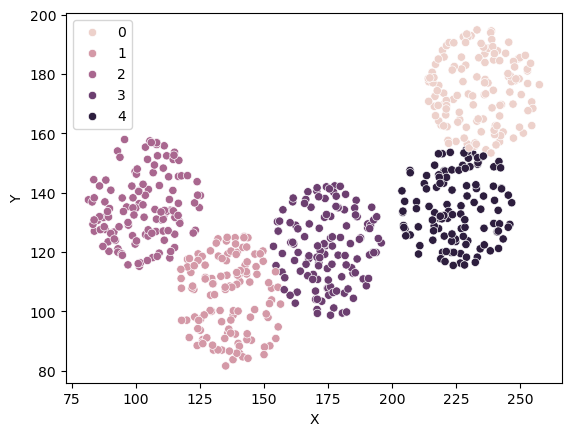

In [5]:
print_instant(instantanee[44], plot=True)

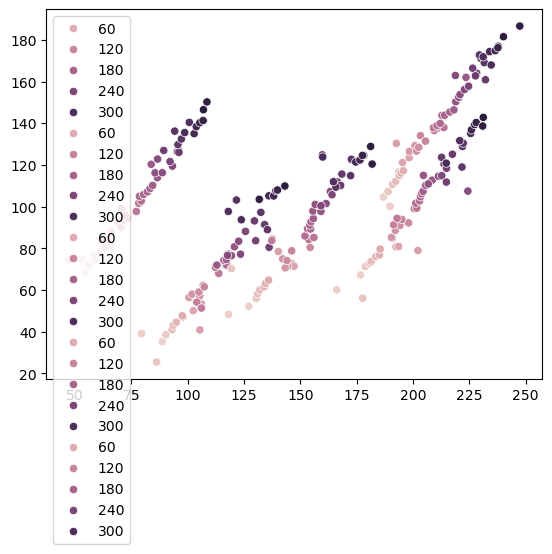

In [6]:
for i in range(1, 50):
    prev_centers = drones_pos[i-1]
    pos, iner = print_instant(instantanee[i], centers=prev_centers)
    drones_pos.append(pos)
    drones_iner.append(iner)
def get_ith(a, n):
    f = []
    for i in a:
        f.append(i[n])
    return f
for i in range(5):
    sns.scatterplot(x=get_ith(get_ith(drones_pos,i),0),y=get_ith(get_ith(drones_pos,i),1), hue=times)


In [7]:
stuff = pd.DataFrame(data={"iner":drones_iner, "pos":drones_pos, "times":times, "papa":timestamps})

distances = []

for i in range(len(drones_pos)):
    dist = []
    for j in range(5):
        x=get_ith(drones_pos, j)[i][0]-get_ith(drones_pos, j)[0][0]
        y=get_ith(drones_pos, j)[i][1]-get_ith(drones_pos, j)[0][1]
        dist.append(np.sqrt(x*x+y*y))
    distances.append(dist)

stuff = pd.DataFrame(data={"iner":drones_iner, "pos":drones_pos, "times":times, "papa":timestamps, "dist":distances})


goodstuff = stuff[stuff["iner"]<2000]
goodstuff

,iner,pos,times,papa,dist
0,653.500079,"[[186.82262314832118, 104.63050811654105], [88...",3,"Jan 26, 2026, 12:00:03 AM","[0.0, 0.0, 0.0, 0.0, 0.0]"
8,55.077383,"[[195.6671960510078, 117.22141615173504], [97....",59,"Jan 26, 2026, 12:00:59 AM","[15.386924155972533, 15.209257253468461, 15.21..."
29,435.123512,"[[218.93899317833677, 150.30392537012756], [12...",207,"Jan 26, 2026, 12:03:27 AM","[55.83477650644889, 55.57825848034257, 55.6061..."
37,24.832707,"[[227.6564348035211, 162.72894505323967], [129...",263,"Jan 26, 2026, 12:04:23 AM","[71.01287593655032, 70.8355655068014, 70.84087..."


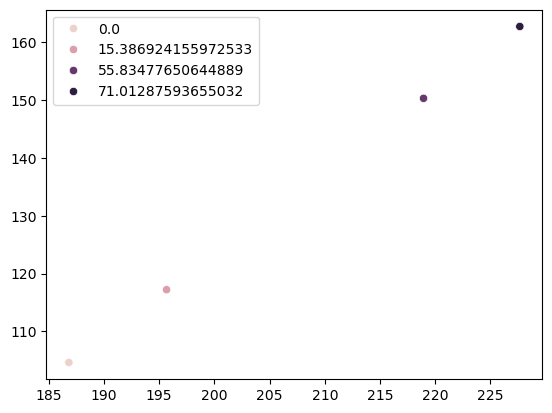

In [8]:
for i in range(1):
    sns.scatterplot(x=get_ith(get_ith(goodstuff['pos'],i),0),y=get_ith(get_ith(goodstuff['pos'],i),1), hue=get_ith(goodstuff['dist'],i))

In [9]:
from sklearn.linear_model import LinearRegression

pred_pos = []
pred_drone = []
pred_pos2 = []
pred_drone2 = []

def format(f):
    return str(int(f*1000)/1000)

def project(w, b, x, y):
    b_n = y-x/w
    x=w*(b_n - b)/(w*w-1)
    y=w*x+b
    if(abs( w*x+b - x/w-b_n)>1):
        print("BRUH")
    return x,y

for i in range(5):
    lr = LinearRegression()

    y_vals = get_ith(get_ith(stuff['pos'],i),1)
    x_vals = get_ith(get_ith(stuff['pos'],i),0)

    for i in range(50):
        dtime = times[i]-times[8]
        speed_x = (x_vals[37]-x_vals[8])/(263-59)
        speed_y = (y_vals[37]-y_vals[8])/(263-59)
        x_new = x_vals[8]+dtime*speed_x
        y_new = y_vals[8]+dtime*speed_y
        y_vals[i]=y_new
        x_vals[i]=x_new
    
    pred_pos.extend([format(x_vals[j]) + "|"+format(y_vals[j]) for j in range(50)])
    pred_drone.extend([j+"|"+str(i) for j in timestamps])

    time_n = 8*60+20
    
    dtime = time_n-times[8]
    speed_x = (x_vals[37]-x_vals[8])/(263-59)
    speed_y = (y_vals[37]-y_vals[8])/(263-59)
    x_new = x_vals[8]+dtime*speed_x
    y_new = y_vals[8]+dtime*speed_y

    pred_pos2.append(format(x_new) + "|"+format(y_new))
    pred_drone2.append("Jan 26, 2026, 12:08:20 AM|"+str(i))

    



In [10]:
rezultat1 = pd.DataFrame(data={
    "id":["GLOBAL"]*2,
    "subtaskID" : ["task1", "task2"],
    "answer" : [50,5]
})

rezultat2 = pd.DataFrame(data={
    "id":pred_drone,
    "subtaskID" : ["task3"]*len(pred_drone),
    "answer" : pred_pos
})

rezultat3 = pd.DataFrame(data={
    "id":pred_drone2,
    "subtaskID" : ["task4"]*len(pred_drone2),
    "answer" : pred_pos2
})

rezultat = pd.concat([rezultat1, rezultat2, rezultat3])

rezultat.to_csv("caca.csv", index=False)

rezultat


,id,subtaskID,answer
0,GLOBAL,task1,50
1,GLOBAL,task2,5
0,"Jan 26, 2026, 12:00:03 AM|49",task3,186.885|104.729
1,"Jan 26, 2026, 12:00:11 AM|49",task3,188.14|106.513
2,"Jan 26, 2026, 12:00:17 AM|49",task3,189.081|107.852
...,...,...,...
0,"Jan 26, 2026, 12:08:20 AM|49",task4,264.82|215.597
1,"Jan 26, 2026, 12:08:20 AM|49",task4,166.818|146.013
2,"Jan 26, 2026, 12:08:20 AM|49",task4,132.661|179.08
3,"Jan 26, 2026, 12:08:20 AM|49",task4,205.026|162.98
